# 03 · Classification: which leads are worth pursuing first?
**Target:** `High_Intent` = 1 when `Conversion_Segment` is High. Deck pilot target: 30 conditional commitments, so a small team must prioritise follow-up.

**Leakage control:** the conversion score is almost exactly a weighted sum of G1 (likelihood), G2 (register) and G3 (share contact), R² ≈ 0.99, so all of these and the score are excluded. Free-text comments (H1) are excluded because they contain sentiment that reveals intent. Gender and nationality are excluded on purpose: outreach priority should not depend on them.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False,'font.size':10})
BLUE,ORANGE,AQUA,YELLOW='#2a78d6','#eb6834','#1baf7a','#eda100'
FIG='../Results/figures/'; SEED=42
c=pd.read_csv('../Dataset/customers.csv')
from sklearn.model_selection import train_test_split,StratifiedKFold,cross_val_score,cross_val_predict
from sklearn.pipeline import Pipeline,make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
y=(c.Conversion_Segment=='High').astype(int)
catf=['Survey_Channel','A5_Area','A8_Occupation','B3_Primary_Channel','B4_Used_Group_Buying_Before','B5_In_Community_WhatsApp_Buying_Group','E2_Most_Important_Feature','F4_Preferred_Payment']
numf=['A2_Age','A6_Household_Size','A7_Monthly_Income_AED','A9_SME_Employees','Is_SME','B1_Monthly_Spend_Eligible_AED','B2_Online_Orders_Per_Month','B6_Max_Delivery_Fee_AED','F1_Min_Discount_To_Switch_Pct','F2_Max_Wait_Days','F3_Membership_WTP_AED_Month']+[x for x in c.columns if x[:2] in('C1','C2','C3','C4','C5','C6','C7','C8') or x.startswith(('CAT_','FEAT_'))]
X=c[numf+catf]; print('features',X.shape[1],'| positive rate',round(y.mean(),3))
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,stratify=y,random_state=SEED)
pre=ColumnTransformer([('n',make_pipeline(SimpleImputer(strategy='median'),StandardScaler()),numf),('c',make_pipeline(SimpleImputer(strategy='constant',fill_value='Missing'),OneHotEncoder(handle_unknown='ignore')),catf)])
models={'Baseline (always majority)':DummyClassifier(strategy='most_frequent'),'Logistic Regression':LogisticRegression(max_iter=2000,class_weight='balanced'),'Decision Tree':DecisionTreeClassifier(max_depth=5,min_samples_leaf=10,class_weight='balanced',random_state=SEED),'Random Forest':RandomForestClassifier(n_estimators=300,min_samples_leaf=5,class_weight='balanced',random_state=SEED,n_jobs=-1)}
cv=StratifiedKFold(5,shuffle=True,random_state=SEED); res=[];pipes={};cms=[]
for n,m in models.items():
    p=Pipeline([('pre',pre),('m',m)]); cvf=cross_val_score(p,Xtr,ytr,cv=cv,scoring='f1').mean(); p.fit(Xtr,ytr); pipes[n]=p
    h=p.predict(Xte); pr=p.predict_proba(Xte)[:,1]; tn,fp,fn,tp=confusion_matrix(yte,h).ravel()
    res.append(dict(Model=n,TP=tp,TN=tn,FP=fp,FN=fn,Accuracy=accuracy_score(yte,h),Precision=precision_score(yte,h,zero_division=0),Recall=recall_score(yte,h),F1=f1_score(yte,h),ROC_AUC=roc_auc_score(yte,pr),CV_F1_Train=cvf))
r=pd.DataFrame(res); r.to_csv('../Results/Classification_Metrics.csv',index=False); print(r.round(3).to_string(index=False))
best=r[r.Model!='Baseline (always majority)'].sort_values('CV_F1_Train',ascending=False).iloc[0].Model; print('selected on training CV F1:',best)

features 52 | positive rate 0.276


                     Model  TP  TN  FP  FN  Accuracy  Precision  Recall    F1  ROC_AUC  CV_F1_Train
Baseline (always majority)   0 217   0  83     0.723      0.000   0.000 0.000    0.500        0.000
       Logistic Regression  65 179  38  18     0.813      0.631   0.783 0.699    0.871        0.645
             Decision Tree  63 164  53  20     0.757      0.543   0.759 0.633    0.778        0.557
             Random Forest  69 164  53  14     0.777      0.566   0.831 0.673    0.867        0.674
selected on training CV F1: Random Forest


## Confusion matrix
The model is selected by cross-validated F1 on training data, so the test set is not used to choose it.

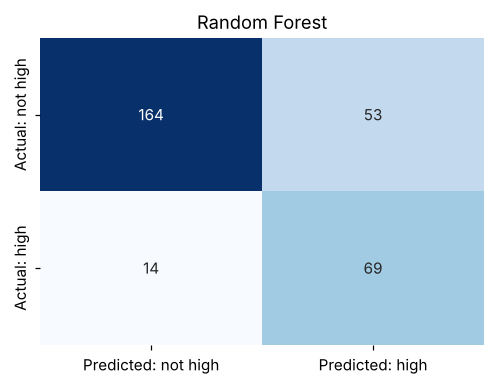

TP 69: truly high-intent leads we would call. FP 53: outreach wasted. FN 14: good leads missed. TN 164: correctly left in nurture.


In [2]:
bp=pipes[best]; tn,fp,fn,tp=confusion_matrix(yte,bp.predict(Xte)).ravel()
fig,ax=plt.subplots(figsize=(4.6,3.6)); sns.heatmap([[tn,fp],[fn,tp]],annot=True,fmt='d',cmap='Blues',cbar=False,xticklabels=['Predicted: not high','Predicted: high'],yticklabels=['Actual: not high','Actual: high'],ax=ax); ax.set_title(best); plt.tight_layout(); plt.savefig(FIG+'confusion_matrix.png'); plt.show()
print(f'TP {tp}: truly high-intent leads we would call. FP {fp}: outreach wasted. FN {fn}: good leads missed. TN {tn}: correctly left in nurture.')

In [3]:
pred=c.loc[Xte.index,['Customer_ID']].assign(Actual_High_Intent=yte.values,Predicted_High_Intent=bp.predict(Xte),Probability=bp.predict_proba(Xte)[:,1]); pred.to_csv('../Results/Predictions.csv',index=False)
oof=cross_val_predict(Pipeline([('pre',pre),('m',models[best])]),X,y,cv=cv,method='predict_proba')[:,1]
c[['Customer_ID']].assign(Lead_Score=oof.round(4),Actual_High_Intent=y).to_csv('../Results/Lead_Scores.csv',index=False)
# importance by permutation on the test set, in original columns
from sklearn.inspection import permutation_importance
pi=permutation_importance(bp,Xte,yte,scoring='roc_auc',n_repeats=10,random_state=SEED)
imp=pd.DataFrame({'Feature':X.columns,'Importance':pi.importances_mean}).sort_values('Importance',ascending=False); imp.to_csv('../Results/Classification_Importance.csv',index=False); print(imp.head(10).round(4).to_string(index=False))
# leakage sanity check: label shuffle should collapse performance
sh=cross_val_score(Pipeline([('pre',pre),('m',models[best])]),Xtr,np.random.default_rng(SEED).permutation(ytr.values),cv=cv,scoring='roc_auc').mean(); print('ROC-AUC with shuffled labels',round(sh,3))

                              Feature  Importance
B5_In_Community_WhatsApp_Buying_Group      0.0284
        F1_Min_Discount_To_Switch_Pct      0.0282
          C2_Willing_To_Wait_For_Deal      0.0144
               C1_Price_Consciousness      0.0112
          B4_Used_Group_Buying_Before      0.0102
              C5_Convenience_Priority      0.0101
               C3_Trust_New_Platforms      0.0073
                  C4_Social_Influence      0.0044
                  CAT_Water_Beverages      0.0013
               FEAT_BNPL_Tabby_Tamara      0.0013


ROC-AUC with shuffled labels 0.485


## Business interpretation
- Accuracy alone misleads: predicting "nobody is high intent" already scores about 72%.
- During cold start a missed buyer (FN) costs more than a wasted message (FP), so recall matters most. The model finds most high-intent leads at the price of some wasted outreach.
- **Automation:** sign-up form → score → founder call list or WhatsApp nurture. The model predicts *stated* intent, so it must be retrained on real pilot payments.